Attached you will find three tables:

erp_* denotes observation-based data (1996-2015) (climate model "driven" with observations)
epp_* denotes model-based data for the present period (1996-2015)


etp_* denotes model-based data for the future period (2081-2100). The scenario used is SSP3-7.0 (high emissions).
The variable names are as follows:

YY- Year it refers to

MM-Month
DD-Day
tas -  daily mean near surface air temperature (K)

tasmax - daily maximum temperature (K)

tasmin - daily minimum temperature (K)

hurs - daily mean relative humidity (%)

sfcwind - daily mean wind speed (m/s)


From the top we will have to conert the temperature (K) into C.
We will crate multiple new csv files where we will be adding new information, never deleting the previous one.

for future reference:

In [2]:
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import csv
import pandas as pd
import math

def celsius (df, coluna_K):
    for coluna in coluna_K:
        coluna_C=coluna.replace('Kelvin', 'Celsius')
        df[coluna_C]=df[coluna]-273.15 #converts Kelvin to Celsius
    return df


def heat_index(T,RH): #temperature in celsius and RH in percentage
    er=1.6 #KPa
    Tr=0.8841*T+(0.19)
    p=(0.0196*T)+0.9031
    es = 0.611 * math.exp(5423 * (1/273.15 - 1/(T + 273.15)))

    HI=Tr+(T-Tr)*((RH*es)/(100*er))**p
    return HI

def create_date_column(df):
    # Garantir que as colunas 'YY', 'MM', 'DD' são inteiros
    df[['YY', 'MM', 'DD']] = df[['YY', 'MM', 'DD']].astype(int)
    
    # Criar uma coluna 'date' com o formato 'YYYY-MM-DD'
    df['date'] = df['YY'].astype(str) + '-' + df['MM'].astype(str).str.zfill(2) + '-' + df['DD'].astype(str).str.zfill(2)
    
    # Converter a coluna 'date' para datetime
    df['date'] = pd.to_datetime(df['date'])
    
    return df
    
csv_files = [
    r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015.csv',
    r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015.csv',
    r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100.csv']

temp_K=['tas', 'tasmax', 'tasmin']

for csv in csv_files:
    df=pd.read_csv(csv)#it reads the csv file (one of the ones that belongs to csv_files list)
    df=celsius (df, temp_K) #it says that the new data frame will have its temperatures changed to celsius
    df['heat_index'] = df.apply(lambda row: heat_index(row['tas'], row['hurs']), axis=1)
    df['heat_index_max'] = df.apply(lambda row: heat_index(row['tasmax'], row['hurs']), axis=1)    
    df[['YY', 'MM', 'DD']] = df[['YY', 'MM', 'DD']].astype(int)
    df['date'] = df['YY'].astype(str) + '-' + df['MM'].astype(str).str.zfill(2) + '-' + df['DD'].astype(str).str.zfill(2)
    df['date'] = pd.to_datetime(df['date'])
    new_csv = csv.replace('.csv', '_WC+HI.csv')
    df.to_csv(new_csv, index=False)
    
# Carregar os arquivos CSV convertidos em DataFrames
df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_WC+HI.csv')
df_epp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')
df_etp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_WC+HI.csv')

# Exibir as primeiras linhas de cada DataFrame
print(df_erp.head())
print(df_epp.head())
print(df_etp.head()) 

     YY  MM  DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996   1   1  14.111902  15.887201  10.946985  86.755997  5.176228   
1  1996   1   2  12.541010  15.109399   8.969110  91.813049  2.046499   
2  1996   1   3  14.728113  16.028497  12.791559  97.225250  3.764771   
3  1996   1   4  14.850671  15.920404  13.415521  94.710892  4.311609   
4  1996   1   5  13.673181  15.552148  12.153009  93.431549  3.309732   

   heat_index  heat_index_max        date  
0   13.907227       15.860420  1996-01-01  
1   12.309026       15.095543  1996-01-02  
2   14.773851       16.266594  1996-01-03  
3   14.863045       16.081471  1996-01-04  
4   13.542273       15.629709  1996-01-05  
     YY  MM  DD        tas     tasmax     tasmin       hurs   sfcwind  \
0  1996   1   1  11.673853  13.337671   9.096735  97.802551  3.527462   
1  1996   1   2   9.494196  11.780542   7.350732  85.961823  2.174941   
2  1996   1   3  12.219019  14.014917  10.674646  95.754532  7.470380   
3  19

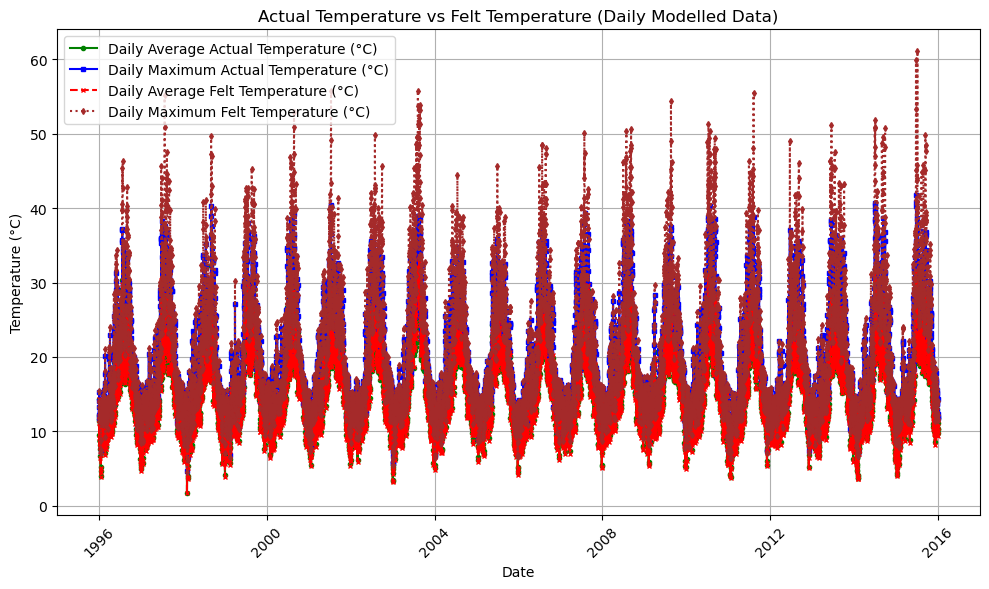

In [3]:
# Plotar o gráfico
#df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_WC+HI.csv')
#df = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')
#df = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_WC+HI.csv')

df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')

# Drop rows with invalid/missing dates
df_epp = df_epp.dropna(subset=['date'])

plt.figure(figsize=(10, 6))
plt.plot(df_epp['date'], df_epp['tas'], label='Daily Average Actual Temperature (°C)', color='green', marker='o', markersize=3, linestyle='-')
plt.plot(df_epp['date'], df_epp['tasmax'], label='Daily Maximum Actual Temperature (°C)', color='blue', marker='s', markersize=3, linestyle='-')
plt.plot(df_epp['date'], df_epp['heat_index'], label='Daily Average Felt Temperature (°C)', color='red', marker='x', markersize=3, linestyle='--')
plt.plot(df_epp['date'], df_epp['heat_index_max'], label='Daily Maximum Felt Temperature (°C)', color='brown', marker='d', markersize=3, linestyle=':')

# Adicionar título e rótulos aos eixos
plt.title(f'Actual Temperature vs Felt Temperature (Daily Modelled Data)')
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.legend()

# Exibir o gráfico
plt.grid(True)
plt.xticks(rotation=45)  # Girar as datas no eixo X para facilitar a leitura
plt.tight_layout()  # Ajusta o layout para não cortar os rótulos
plt.show()

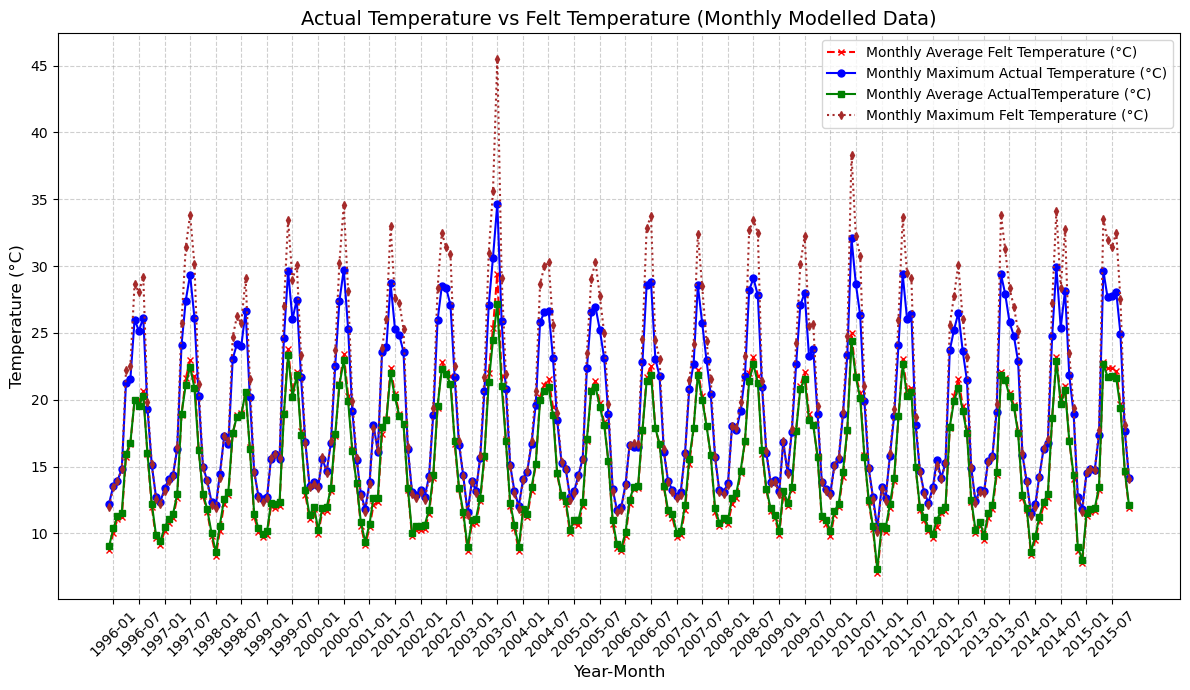

In [8]:
# Plotar o gráfico
#df_erp = pd.read_csv(r'C:\Users\maria\HW_Data\Data\erp_timeseries_1996-2015_WC+HI.csv')
#df = pd.read_csv(r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')
#df = pd.read_csv(r'C:\Users\maria\HW_Data\Data\etp_timeseries_2081-2100_WC+HI.csv')

df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')
# Create a year-month period and compute monthly aggregates
df_epp['year_month'] = df_epp['date'].dt.to_period('M')
df_monthly = df_epp.groupby('year_month').mean().reset_index()

# Convert 'year_month' to datetime for better x-axis control
df_monthly['year_month'] = pd.to_datetime(df_monthly['year_month'].astype(str))

# Drop rows with invalid/missing dates
df_epp = df_epp.dropna(subset=['date'])

plt.figure(figsize=(12, 7))
# Plot for Monthly Heat Index
plt.plot(df_monthly['year_month'], df_monthly['heat_index'], 
         label='Monthly Average Felt Temperature (°C)', color='red', marker='x', markersize=5, linestyle='--')

# Plot for Monthly Maximum Temperature
plt.plot(df_monthly['year_month'], df_monthly['tasmax'], 
         label='Monthly Maximum Actual Temperature (°C)', color='blue', marker='o', markersize=5, linestyle='-')

# Plot for Monthly Average Temperature
plt.plot(df_monthly['year_month'], df_monthly['tas'], 
         label='Monthly Average ActualTemperature (°C)', color='green', marker='s', markersize=4, linestyle='-')

# Plot for Monthly Heat Index with Maximum Temperature
plt.plot(df_monthly['year_month'], df_monthly['heat_index_max'], 
         label='Monthly Maximum Felt Temperature (°C)', color='brown', marker='d', markersize=4, linestyle=':')
# Add title and labels
plt.title('Actual Temperature vs Felt Temperature (Monthly Modelled Data)', fontsize=14)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)

# Customize x-axis ticks to show fewer, more meaningful labels
tick_positions = pd.date_range(start=df_monthly['year_month'].min(), 
                               end=df_monthly['year_month'].max(), 
                               freq='6M')
plt.xticks(ticks=tick_positions, labels=tick_positions.strftime('%Y-%m'), rotation=45, fontsize=10)

# Add legend
plt.legend(fontsize=10)

# Enhance grid and y-axis formatting
plt.grid(True, linestyle='--', alpha=0.6)
plt.yticks(fontsize=10)

# Ensure layout is tidy
plt.tight_layout()

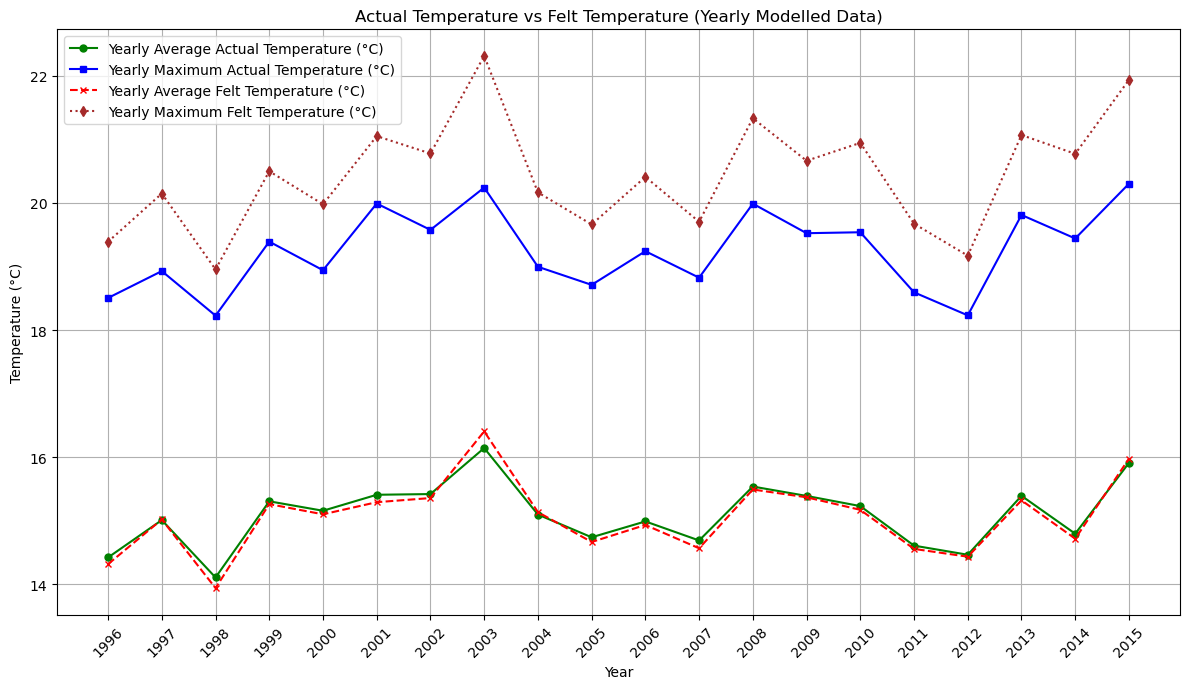

    year_month      YY    MM    DD        tas     tasmax     tasmin  \
0   1996-01-01  1996.0   1.0  16.0   9.034803  12.227777   6.381587   
1   1996-02-01  1996.0   2.0  15.0  10.374265  13.578927   7.756012   
2   1996-03-01  1996.0   3.0  16.0  11.308528  13.941093   8.693717   
3   1996-04-01  1996.0   4.0  15.5  11.552563  14.853699   8.752576   
4   1996-05-01  1996.0   5.0  16.0  15.953791  21.269036  11.094240   
..         ...     ...   ...   ...        ...        ...        ...   
235 2015-08-01  2015.0   8.0  16.0  21.808458  27.735926  17.210832   
236 2015-09-01  2015.0   9.0  15.5  21.625244  28.076619  15.927764   
237 2015-10-01  2015.0  10.0  16.0  19.395667  24.952902  14.654847   
238 2015-11-01  2015.0  11.0  15.5  14.638581  17.636691  11.840780   
239 2015-12-01  2015.0  12.0  16.0  12.107276  14.161076  10.079486   

          hurs   sfcwind  heat_index  heat_index_max                date  year  
0    91.844722  3.012535    8.761784       12.002539 1996-01-16 00

In [10]:
# Ensure 'date' is in datetime format and handle missing values
df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')
df_epp = df_epp.dropna(subset=['date'])

# Group by year and calculate yearly averages
df_epp['year'] = df_epp['date'].dt.to_period('Y')
df_yearly = df_epp.groupby('year').mean().reset_index()
df_yearly['year'] = df_yearly['year'].astype(str)

# Plot the graph
plt.figure(figsize=(12, 7))

# Plot for Yearly Average Temperature
plt.plot(df_yearly['year'], df_yearly['tas'], 
         label='Yearly Average Actual Temperature (°C)', color='green', marker='o', markersize=5, linestyle='-')

# Plot for Yearly Maximum Temperature
plt.plot(df_yearly['year'], df_yearly['tasmax'], 
         label='Yearly Maximum Actual Temperature (°C)', color='blue', marker='s', markersize=5, linestyle='-')

# Plot for Yearly Heat Index
plt.plot(df_yearly['year'], df_yearly['heat_index'], 
         label='Yearly Average Felt Temperature (°C)', color='red', marker='x', markersize=5, linestyle='--')

# Plot for Yearly Maximum Heat Index
plt.plot(df_yearly['year'], df_yearly['heat_index_max'], 
         label='Yearly Maximum Felt Temperature (°C)', color='brown', marker='d', markersize=5, linestyle=':')

# Add title and axis labels
plt.title(f'Actual Temperature vs Felt Temperature (Yearly Modelled Data)')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.legend()

# Show grid and rotate x-axis labels
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print (df_monthly)

Function to return the warmest months ()

And if i only want specific months (the warmest- june, july, augus, september)-6,7,8,9

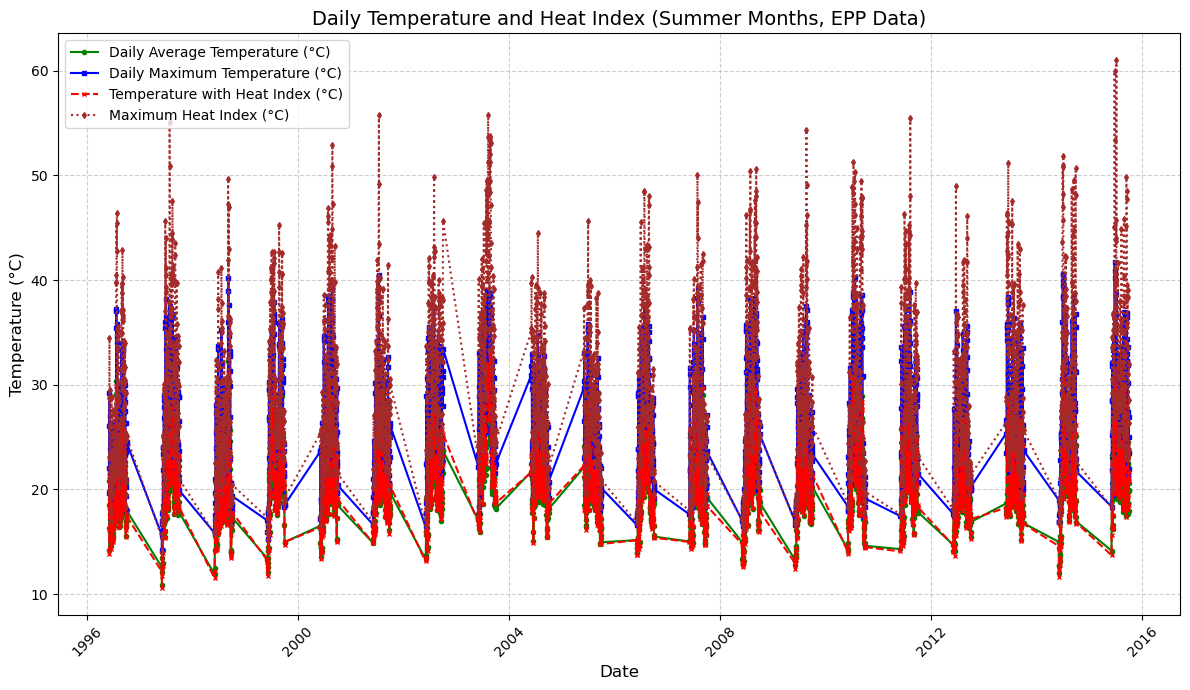

In [6]:
# Ensure 'date' is in datetime format and handle missing values
df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')
df_epp = df_epp.dropna(subset=['date'])

# Filter data for summer months (June to September)
summer_months = [6, 7, 8, 9]  # June to September
df_summer = df_epp[df_epp['date'].dt.month.isin(summer_months)]

# Create the plot
plt.figure(figsize=(12, 7))

# Plot for Daily Average Temperature
plt.plot(df_summer['date'], df_summer['tas'], 
         label='Daily Average Temperature (°C)', color='green', marker='o', markersize=3, linestyle='-')

# Plot for Daily Maximum Temperature
plt.plot(df_summer['date'], df_summer['tasmax'], 
         label='Daily Maximum Temperature (°C)', color='blue', marker='s', markersize=3, linestyle='-')

# Plot for Heat Index
plt.plot(df_summer['date'], df_summer['heat_index'], 
         label='Temperature with Heat Index (°C)', color='red', linestyle='--', marker='x', markersize=3)

# Plot for Maximum Heat Index
plt.plot(df_summer['date'], df_summer['heat_index_max'], 
         label='Maximum Heat Index (°C)', color='brown', marker='d', markersize=3, linestyle=':')

# Add title and labels
plt.title('Daily Temperature and Heat Index (Summer Months, EPP Data)', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)

# Add legend
plt.legend(fontsize=10)

# Enhance grid and rotate x-axis labels
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(rotation=45, fontsize=10)
plt.yticks(fontsize=10)

# Ensure layout is tidy
plt.tight_layout()

# Show the plot
plt.show()

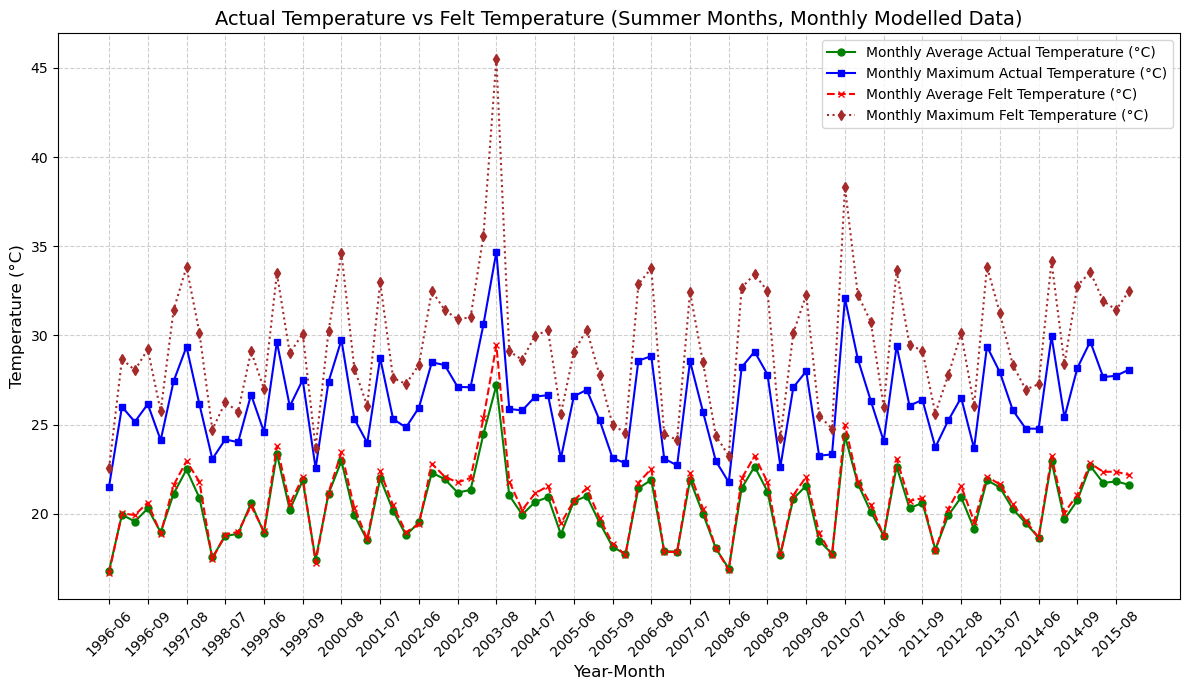

In [11]:
# Ensure 'date' column is in datetime format
df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')
df_epp = df_epp.dropna(subset=['date'])

# Filter for specific months (June, July, August, September)
summer_months = [6, 7, 8, 9]
df_summer = df_epp[df_epp['date'].dt.month.isin(summer_months)].copy()

# Group by year and month
df_summer['year_month'] = df_summer['date'].dt.to_period('M')
df_monthly = df_summer.groupby('year_month').mean().reset_index()

# Convert 'year_month' to string for plotting
df_monthly['year_month'] = df_monthly['year_month'].astype(str)

# Check if required columns exist
required_columns = ['tas', 'tasmax', 'heat_index', 'heat_index_max']
missing_columns = [col for col in required_columns if col not in df_monthly.columns]
if missing_columns:
    raise ValueError(f"Required columns {missing_columns} are missing in the dataset.")

# Plot the graph
plt.figure(figsize=(12, 7))

# Plot for Monthly Average Temperature
plt.plot(df_monthly['year_month'], df_monthly['tas'], 
         label='Monthly Average Actual Temperature (°C)', color='green', marker='o', markersize=5, linestyle='-')

# Plot for Monthly Maximum Temperature
plt.plot(df_monthly['year_month'], df_monthly['tasmax'], 
         label='Monthly Maximum Actual Temperature (°C)', color='blue', marker='s', markersize=5, linestyle='-')

# Plot for Heat Index
plt.plot(df_monthly['year_month'], df_monthly['heat_index'], 
         label='Monthly Average Felt Temperature (°C)', color='red', linestyle='--', marker='x', markersize=5)

# Plot for Maximum Heat Index
plt.plot(df_monthly['year_month'], df_monthly['heat_index_max'], 
         label='Monthly Maximum Felt Temperature (°C)', color='brown', marker='d', markersize=5, linestyle=':')

# Add title and axis labels
plt.title('Actual Temperature vs Felt Temperature (Summer Months, Monthly Modelled Data)', fontsize=14)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)

# Add legend
plt.legend(fontsize=10)

# Show grid and rotate x-axis labels
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(ticks=range(0, len(df_monthly['year_month']), 3), rotation=45, fontsize=10)
plt.yticks(fontsize=10)

# Ensure layout is tidy
plt.tight_layout()

# Show the plot
plt.show()

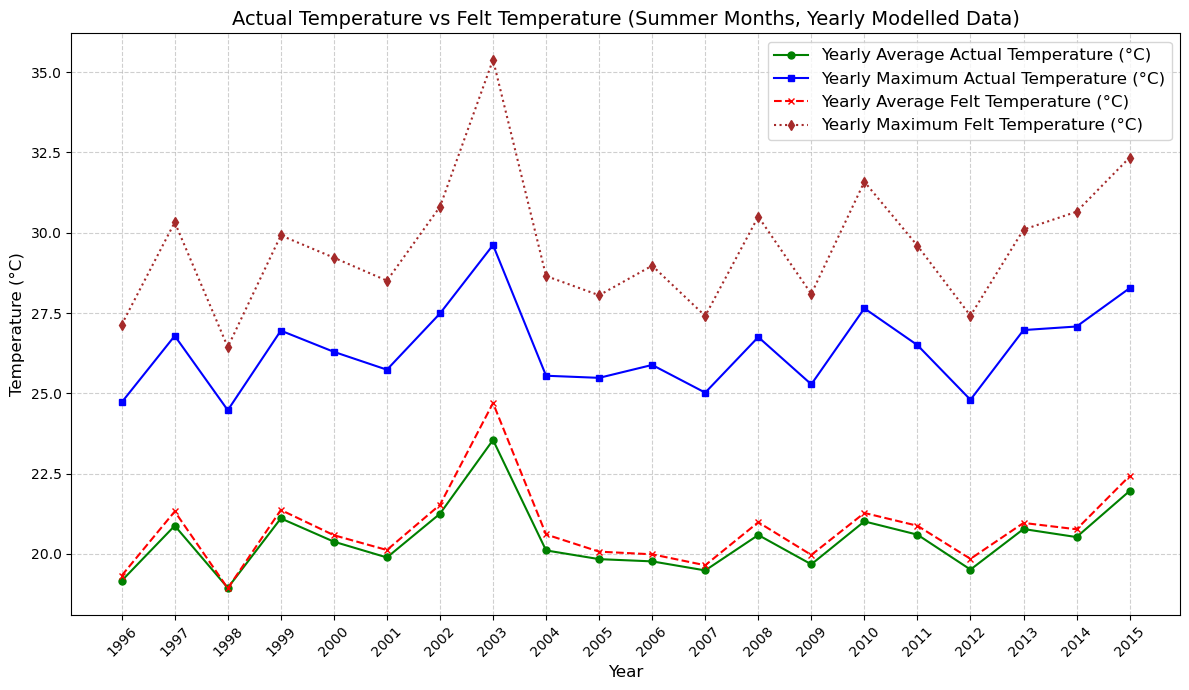

In [14]:
# Ensure 'date' column is in datetime format
df_epp['date'] = pd.to_datetime(df_epp['date'], errors='coerce')
df_epp = df_epp.dropna(subset=['date'])

# Filter for specific months (June, July, August, September)
summer_months = [6, 7, 8, 9]
df_summer = df_epp[df_epp['date'].dt.month.isin(summer_months)].copy()

# Extract year and calculate yearly averages for the warm months
df_summer['year'] = df_summer['date'].dt.year
df_yearly = df_summer.groupby('year').mean().reset_index()

# Check if required columns exist
required_columns = ['tas', 'tasmax', 'heat_index', 'heat_index_max']
missing_columns = [col for col in required_columns if col not in df_yearly.columns]
if missing_columns:
    raise ValueError(f"Required columns {missing_columns} are missing in the dataset.")

# Plot the graph
plt.figure(figsize=(12, 7))

# Plot for Yearly Average Temperature
plt.plot(df_yearly['year'], df_yearly['tas'], 
         label='Yearly Average Actual Temperature (°C)', color='green', marker='o', markersize=5, linestyle='-')

# Plot for Yearly Maximum Temperature
plt.plot(df_yearly['year'], df_yearly['tasmax'], 
         label='Yearly Maximum Actual Temperature (°C)', color='blue', marker='s', markersize=5, linestyle='-')

# Plot for Yearly Heat Index
plt.plot(df_yearly['year'], df_yearly['heat_index'], 
         label='Yearly Average Felt Temperature (°C)', color='red', marker='x', markersize=5, linestyle='--')

# Plot for Maximum Heat Index
plt.plot(df_yearly['year'], df_yearly['heat_index_max'], 
         label='Yearly Maximum Felt Temperature (°C)', color='brown', marker='d', markersize=5, linestyle=':')

# Add title and axis labels
plt.title('Actual Temperature vs Felt Temperature (Summer Months, Yearly Modelled Data)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)

# Add legend
plt.legend(fontsize=12)

# Show grid and adjust x-axis ticks
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(df_yearly['year'], rotation=45, fontsize=10)  # Rotate for better readability
plt.yticks(fontsize=10)

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

ACIMA DE 5 ACTUAL

In [11]:
def analyze_heat_wave_actual_5(csv_file):
    """
    Analyze heat waves from a daily temperature dataset.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    dict: Total number of heat waves and details about each heat wave.
    """
    # Read and prepare the data
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    daily_differences = []
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['tasmax'] >= row['tas'] + 5:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            daily_differences.append(row['tasmax'] - row['tas'])
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                avg_degrees_above = sum(daily_differences) / len(daily_differences)
                max_degree_above = max(daily_differences)
                min_degree_above = min(daily_differences)
                heat_wave_end = row['date'] - pd.Timedelta(days=1)
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "avg_degrees_above_threshold": avg_degrees_above,
                    "max_degree_above": max_degree_above,
                    "min_degree_above": min_degree_above
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            daily_differences = []
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        avg_degrees_above = sum(daily_differences) / len(daily_differences)
        max_degree_above = max(daily_differences)
        min_degree_above = min(daily_differences)
        heat_wave_end = row['date'] - pd.Timedelta(days=1)
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "avg_degrees_above_threshold": avg_degrees_above,
            "max_degree_above": max_degree_above,
            "min_degree_above": min_degree_above
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }

In [12]:
analyze_heat_wave_actual_5 (r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')

{'total_heat_waves': 115,
 'heat_waves': [{'start_date': Timestamp('1996-05-23 00:00:00'),
   'end_date': Timestamp('1996-05-30 00:00:00'),
   'duration': 8,
   'avg_degrees_above_threshold': 6.747333526611326,
   'max_degree_above': 8.074859619140625,
   'min_degree_above': 5.00921630859375},
  {'start_date': Timestamp('1996-06-01 00:00:00'),
   'end_date': Timestamp('1996-06-08 00:00:00'),
   'duration': 8,
   'avg_degrees_above_threshold': 6.546478271484382,
   'max_degree_above': 8.390960693359379,
   'min_degree_above': 5.015411376953182},
  {'start_date': Timestamp('1996-07-17 00:00:00'),
   'end_date': Timestamp('1996-07-26 00:00:00'),
   'duration': 10,
   'avg_degrees_above_threshold': 8.240066528320309,
   'max_degree_above': 11.251556396484375,
   'min_degree_above': 5.2731018066406286},
  {'start_date': Timestamp('1996-08-24 00:00:00'),
   'end_date': Timestamp('1996-09-08 00:00:00'),
   'duration': 16,
   'avg_degrees_above_threshold': 7.850875854492184,
   'max_degree_abo

ACIMA DE 5 FELT

In [13]:
def analyze_heat_wave_felt_5(csv_file):
    """
    Analyze heat waves from a daily temperature dataset.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    dict: Total number of heat waves and details about each heat wave.
    """
    # Read and prepare the data
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    daily_differences = []
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['heat_index_max'] >= row['heat_index'] + 5:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            daily_differences.append(row['heat_index_max'] - row['heat_index'])
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                avg_degrees_above = sum(daily_differences) / len(daily_differences)
                max_degree_above = max(daily_differences)
                min_degree_above = min(daily_differences)
                heat_wave_end = row['date'] - pd.Timedelta(days=1)
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "avg_degrees_above_threshold": avg_degrees_above,
                    "max_degree_above": max_degree_above,
                    "min_degree_above": min_degree_above
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            daily_differences = []
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        avg_degrees_above = sum(daily_differences) / len(daily_differences)
        max_degree_above = max(daily_differences)
        min_degree_above = min(daily_differences)
        heat_wave_end = row['date'] - pd.Timedelta(days=1)
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "avg_degrees_above_threshold": avg_degrees_above,
            "max_degree_above": max_degree_above,
            "min_degree_above": min_degree_above
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }

In [14]:
analyze_heat_wave_felt_5 (r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')

{'total_heat_waves': 151,
 'heat_waves': [{'start_date': Timestamp('1996-05-05 00:00:00'),
   'end_date': Timestamp('1996-05-10 00:00:00'),
   'duration': 6,
   'avg_degrees_above_threshold': 8.29590927897239,
   'max_degree_above': 10.723866354135229,
   'min_degree_above': 5.2911033888465635},
  {'start_date': Timestamp('1996-05-19 00:00:00'),
   'end_date': Timestamp('1996-05-30 00:00:00'),
   'duration': 12,
   'avg_degrees_above_threshold': 8.234155283603625,
   'max_degree_above': 10.915908836778346,
   'min_degree_above': 6.09486607812887},
  {'start_date': Timestamp('1996-06-01 00:00:00'),
   'end_date': Timestamp('1996-06-08 00:00:00'),
   'duration': 8,
   'avg_degrees_above_threshold': 8.697399263273931,
   'max_degree_above': 13.161027587616076,
   'min_degree_above': 6.034768966594612},
  {'start_date': Timestamp('1996-07-17 00:00:00'),
   'end_date': Timestamp('1996-08-07 00:00:00'),
   'duration': 22,
   'avg_degrees_above_threshold': 10.870622233402495,
   'max_degree_a

ACIMA DE 8 ACTUAL

In [15]:
def analyze_heat_wave_actual_8(csv_file):
    """
    Analyze heat waves from a daily temperature dataset.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    dict: Total number of heat waves and details about each heat wave.
    """
    # Read and prepare the data
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    daily_differences = []
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['tasmax'] >= row['tas'] +8:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            daily_differences.append(row['tasmax'] - row['tas'])
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                avg_degrees_above = sum(daily_differences) / len(daily_differences)
                max_degree_above = max(daily_differences)
                min_degree_above = min(daily_differences)
                heat_wave_end = row['date'] - pd.Timedelta(days=1)
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "avg_degrees_above_threshold": avg_degrees_above,
                    "max_degree_above": max_degree_above,
                    "min_degree_above": min_degree_above
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            daily_differences = []
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        avg_degrees_above = sum(daily_differences) / len(daily_differences)
        max_degree_above = max(daily_differences)
        min_degree_above = min(daily_differences)
        heat_wave_end = row['date'] - pd.Timedelta(days=1)
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "avg_degrees_above_threshold": avg_degrees_above,
            "max_degree_above": max_degree_above,
            "min_degree_above": min_degree_above
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }

In [16]:
analyze_heat_wave_actual_8 (r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')

{'total_heat_waves': 10,
 'heat_waves': [{'start_date': Timestamp('1997-08-09 00:00:00'),
   'end_date': Timestamp('1997-08-17 00:00:00'),
   'duration': 9,
   'avg_degrees_above_threshold': 9.158338758680562,
   'max_degree_above': 10.791839599609375,
   'min_degree_above': 8.063537597656303},
  {'start_date': Timestamp('2002-06-20 00:00:00'),
   'end_date': Timestamp('2002-06-26 00:00:00'),
   'duration': 7,
   'avg_degrees_above_threshold': 9.117723737444189,
   'max_degree_above': 9.737640380859322,
   'min_degree_above': 8.175109863281246},
  {'start_date': Timestamp('2002-07-29 00:00:00'),
   'end_date': Timestamp('2002-08-03 00:00:00'),
   'duration': 6,
   'avg_degrees_above_threshold': 9.231836954752604,
   'max_degree_above': 10.393310546875,
   'min_degree_above': 8.013580322265625},
  {'start_date': Timestamp('2003-08-02 00:00:00'),
   'end_date': Timestamp('2003-08-09 00:00:00'),
   'duration': 8,
   'avg_degrees_above_threshold': 9.255077362060547,
   'max_degree_above': 

ACIMA DE 8 FELT

In [17]:
def analyze_heat_wave_felt_8(csv_file):
    """
    Analyze heat waves from a daily temperature dataset.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    dict: Total number of heat waves and details about each heat wave.
    """
    # Read and prepare the data
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    daily_differences = []
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['heat_index_max'] >= row['heat_index'] +8:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            daily_differences.append(row['heat_index_max'] - row['heat_index'])
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                avg_degrees_above = sum(daily_differences) / len(daily_differences)
                max_degree_above = max(daily_differences)
                min_degree_above = min(daily_differences)
                heat_wave_end = row['date'] - pd.Timedelta(days=1)
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "avg_degrees_above_threshold": avg_degrees_above,
                    "max_degree_above": max_degree_above,
                    "min_degree_above": min_degree_above
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            daily_differences = []
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        avg_degrees_above = sum(daily_differences) / len(daily_differences)
        max_degree_above = max(daily_differences)
        min_degree_above = min(daily_differences)
        heat_wave_end = row['date'] - pd.Timedelta(days=1)
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "avg_degrees_above_threshold": avg_degrees_above,
            "max_degree_above": max_degree_above,
            "min_degree_above": min_degree_above
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }

In [18]:
analyze_heat_wave_felt_8 (r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')

{'total_heat_waves': 66,
 'heat_waves': [{'start_date': Timestamp('1996-07-20 00:00:00'),
   'end_date': Timestamp('1996-07-26 00:00:00'),
   'duration': 7,
   'avg_degrees_above_threshold': 15.59479040241229,
   'max_degree_above': 22.112116466468986,
   'min_degree_above': 9.895563932043764},
  {'start_date': Timestamp('1996-08-24 00:00:00'),
   'end_date': Timestamp('1996-09-07 00:00:00'),
   'duration': 15,
   'avg_degrees_above_threshold': 12.945388808500724,
   'max_degree_above': 17.4489184230018,
   'min_degree_above': 9.631828488494023},
  {'start_date': Timestamp('1997-06-24 00:00:00'),
   'end_date': Timestamp('1997-07-04 00:00:00'),
   'duration': 11,
   'avg_degrees_above_threshold': 11.22105954399189,
   'max_degree_above': 18.56795776263856,
   'min_degree_above': 8.105154586681842},
  {'start_date': Timestamp('1997-08-03 00:00:00'),
   'end_date': Timestamp('1997-08-18 00:00:00'),
   'duration': 16,
   'avg_degrees_above_threshold': 14.149934197144722,
   'max_degree_ab

ACIMA DE 10 ACTUAL

In [19]:
def analyze_heat_wave_actual_10(csv_file):
    """
    Analyze heat waves from a daily temperature dataset.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    dict: Total number of heat waves and details about each heat wave.
    """
    # Read and prepare the data
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    daily_differences = []
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['tasmax'] >= row['tas'] +10:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            daily_differences.append(row['tasmax'] - row['tas'])
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                avg_degrees_above = sum(daily_differences) / len(daily_differences)
                max_degree_above = max(daily_differences)
                min_degree_above = min(daily_differences)
                heat_wave_end = row['date'] - pd.Timedelta(days=1)
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "avg_degrees_above_threshold": avg_degrees_above,
                    "max_degree_above": max_degree_above,
                    "min_degree_above": min_degree_above
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            daily_differences = []
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        avg_degrees_above = sum(daily_differences) / len(daily_differences)
        max_degree_above = max(daily_differences)
        min_degree_above = min(daily_differences)
        heat_wave_end = row['date'] - pd.Timedelta(days=1)
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "avg_degrees_above_threshold": avg_degrees_above,
            "max_degree_above": max_degree_above,
            "min_degree_above": min_degree_above
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }

In [20]:
analyze_heat_wave_actual_10 (r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')

{'total_heat_waves': 1,
 'heat_waves': [{'start_date': Timestamp('2010-08-28 00:00:00'),
   'end_date': Timestamp('2010-09-05 00:00:00'),
   'duration': 9,
   'avg_degrees_above_threshold': 11.01672024197048,
   'max_degree_above': 12.350219726562496,
   'min_degree_above': 10.34783935546875}]}

ACIMA DE 10 FELT

In [21]:
def analyze_heat_wave_felt_10(csv_file):
    """
    Analyze heat waves from a daily temperature dataset.

    Parameters:
    csv_file (str): Path to the CSV file containing the data.

    Returns:
    dict: Total number of heat waves and details about each heat wave.
    """
    # Read and prepare the data
    df = pd.read_csv(csv_file)
    df['date'] = pd.to_datetime(df['date'])
    
    # Initialize variables
    heat_waves = []
    consecutive_days = 0
    daily_differences = []
    heat_wave_start = None

    # Iterate over rows to detect heat waves
    for index, row in df.iterrows():
        if row['heat_index_max'] >= row['heat_index'] +10:
            if consecutive_days == 0:
                heat_wave_start = row['date']  # Record start date of the heat wave
            consecutive_days += 1
            daily_differences.append(row['heat_index_max'] - row['heat_index'])
        else:
            if consecutive_days >= 6:
                # Store heat wave details
                avg_degrees_above = sum(daily_differences) / len(daily_differences)
                max_degree_above = max(daily_differences)
                min_degree_above = min(daily_differences)
                heat_wave_end = row['date'] - pd.Timedelta(days=1)
                heat_waves.append({
                    "start_date": heat_wave_start,
                    "end_date": heat_wave_end,
                    "duration": consecutive_days,
                    "avg_degrees_above_threshold": avg_degrees_above,
                    "max_degree_above": max_degree_above,
                    "min_degree_above": min_degree_above
                })
            # Reset for the next potential heat wave
            consecutive_days = 0
            daily_differences = []
            heat_wave_start = None

    # Check if the last streak is a heat wave
    if consecutive_days >= 6:
        avg_degrees_above = sum(daily_differences) / len(daily_differences)
        max_degree_above = max(daily_differences)
        min_degree_above = min(daily_differences)
        heat_wave_end = row['date'] - pd.Timedelta(days=1)
        heat_waves.append({
            "start_date": heat_wave_start,
            "end_date": heat_wave_end,
            "duration": consecutive_days,
            "avg_degrees_above_threshold": avg_degrees_above,
            "max_degree_above": max_degree_above,
            "min_degree_above": min_degree_above
        })

    # Return the analysis results
    return {
        "total_heat_waves": len(heat_waves),
        "heat_waves": heat_waves
    }

In [22]:
analyze_heat_wave_felt_10 (r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')

{'total_heat_waves': 38,
 'heat_waves': [{'start_date': Timestamp('1996-08-25 00:00:00'),
   'end_date': Timestamp('1996-09-07 00:00:00'),
   'duration': 14,
   'avg_degrees_above_threshold': 13.182071688501201,
   'max_degree_above': 17.4489184230018,
   'min_degree_above': 10.036774572582402},
  {'start_date': Timestamp('1997-08-04 00:00:00'),
   'end_date': Timestamp('1997-08-17 00:00:00'),
   'duration': 14,
   'avg_degrees_above_threshold': 14.925202387191089,
   'max_degree_above': 21.136130499247876,
   'min_degree_above': 10.162223698714165},
  {'start_date': Timestamp('1998-07-18 00:00:00'),
   'end_date': Timestamp('1998-07-23 00:00:00'),
   'duration': 6,
   'avg_degrees_above_threshold': 12.941188444642995,
   'max_degree_above': 15.145982555549587,
   'min_degree_above': 11.263686492600371},
  {'start_date': Timestamp('1998-08-31 00:00:00'),
   'end_date': Timestamp('1998-09-05 00:00:00'),
   'duration': 6,
   'avg_degrees_above_threshold': 14.83603051387495,
   'max_degre

QUANDO SÃO 6 DIAS ACIMA DE 5 GRAUS

In [24]:
analyze_heat_wave (r'C:\Users\maria\HW_Data\Data\epp_timeseries_1996-2015_WC+HI.csv')

{'total_heat_waves': 115,
 'heat_waves': [{'start_date': Timestamp('1996-05-23 00:00:00'),
   'end_date': Timestamp('1996-05-30 00:00:00'),
   'duration': 8,
   'avg_degrees_above_threshold': 6.747333526611326,
   'max_degree_above': 8.074859619140625,
   'min_degree_above': 5.00921630859375},
  {'start_date': Timestamp('1996-06-01 00:00:00'),
   'end_date': Timestamp('1996-06-08 00:00:00'),
   'duration': 8,
   'avg_degrees_above_threshold': 6.546478271484382,
   'max_degree_above': 8.390960693359379,
   'min_degree_above': 5.015411376953182},
  {'start_date': Timestamp('1996-07-17 00:00:00'),
   'end_date': Timestamp('1996-07-26 00:00:00'),
   'duration': 10,
   'avg_degrees_above_threshold': 8.240066528320309,
   'max_degree_above': 11.251556396484375,
   'min_degree_above': 5.2731018066406286},
  {'start_date': Timestamp('1996-08-24 00:00:00'),
   'end_date': Timestamp('1996-09-08 00:00:00'),
   'duration': 16,
   'avg_degrees_above_threshold': 7.850875854492184,
   'max_degree_abo

QUANDO SÃO 6 DIAS ACIMA DE 8 GRAUS